# 12 Time-resolved spectra of GRB 230307A

The precursor work (08-11) extended to the whole burst: Band fits in every time window Dichiara use, so
I can reproduce their Table 2 and the E_peak panel of their Fig. 2, and end with one table of E_peak per
window that can be joined to the MVT values.

Same recipe as for the precursor: n6, n8, na and b1; cubic background per channel on -89 to -7 s and
+162 to +273 s; Poisson likelihood with the background fixed (P-stat); NaI 8-900 keV and BGO 200 keV-40 MeV.

What's new for the main emission:
- 14 windows: Dichiara's 12 spectral intervals (Table 2), plus the two MVT intervals of their Table 1 that
  aren't in Table 2 (7-18 s and 18-40 s). Their Fig. 2 plots E_peak for 7-18 s, so those two are needed to
  reproduce it and to put E_peak against the published MVT.
- Two windows cross the boundary between response matrices at 30.40 s, so they get a counts-weighted
  response.
- The main emission is up to five times brighter than the precursor, so dead time, data gaps and the
  stability of the fits need checking window by window.
- Systematic errors, Comptonized vs Band, detector-by-detector fits, and a check against the official GBM
  catalogue fits.
- Finally the precursor's own structure: where it starts and ends, and the spectra of its two pulses.

The windows and detectors here are Dichiara's, so that the table can be compared with theirs. Notebook 15 checks what
that choice costs: the GBM team flag more of the burst than 3-7 s, and recommend only na and b1 for it.

In [1]:
import subprocess
import warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.optimize import minimize
from scipy.stats import spearmanr

from gdt.core.pha import Bak
from gdt.core.data_primitives import TimeBins
from gdt.core.binning.unbinned import bin_by_edges
from gdt.misc.bayesian_blocks import bayesian_blocks
from gdt.missions.fermi.gbm.tte import GbmTte
from gdt.core.spectra.functions import Band, Comptonized
from gdt.missions.fermi.gbm.response import GbmRsp2

from settings import (DATA_DIR, BURST_ID, CODE_DIR, FIGURE_DIR, BKG_WINDOWS, BKG_ORDER, PRECURSOR,
                      BAD_TIME_INTERVAL, GBM_PILEUP, SOFT_BAND, HARD_BAND, SOFT_DETECTORS, HARD_DETECTORS,
                      SPECTRAL_DETECTORS, FIT_RANGE_NAI, FIT_RANGE_BGO, FLUX_RANGE, REDSHIFT,
                      WINDOWS_FILE, load_windows)
from spectral_fit_tools import (make_spectra, window_response, write_rsp, rsp2_path, channel_mask,
                                fit_model, scaled_starts, cstat, covariance, profile_error,
                                flux_with_error, energy_flux, load_spectra, BandLowBreak)
from lightcurve_tools import (aligned_bin_edges, band_counts, live_fraction, fit_background,
                              background_in_band, data_gaps, tte_path)

OUT_DIR = CODE_DIR / "spectra" / "time_resolved"
OUT_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 200)

# Dichiara et al. (2023) Table 2, Band fits. Flux at 10-1000 keV in 1e-5 erg/cm2/s.
TABLE2 = pd.DataFrame([
    ("pre", -0.064, 0.320, 3.324, 0.038, 170.3, 4.7, -0.63, 0.04, -2.95, 0.09, 563.1, 480),
    ("m01", 0.320, 3.0, 11.96, 0.03, 914.6, 5.4, -0.47, 0.01, -5.5, 0.3, 954.4, 485),
    ("m02", 7.0, 9.0, 17.48, 0.04, 968.0, 6.6, -0.71, 0.01, -4.5, 0.1, 928.5, 485),
    ("m03", 9.0, 11.0, 15.77, 0.04, 946.8, 6.7, -0.73, 0.01, -4.8, 0.2, 1024.2, 485),
    ("m04", 11.0, 13.0, 11.70, 0.03, 804.5, 6.8, -0.90, 0.01, -5.0, 0.4, 1225.3, 485),
    ("m05", 13.0, 15.0, 9.533, 0.031, 781.7, 8.4, -1.07, 0.01, -4.8, 0.4, 1202.0, 485),
    ("m06", 15.0, 18.5, 4.916, 0.016, 634.6, 8.0, -1.17, 0.01, -4.5, 0.4, 1185.2, 485),
    ("m07", 18.5, 22.0, 4.592, 0.016, 617.2, 8.3, -1.23, 0.01, -5.0, 0.9, 1260.2, 485),
    ("m08", 22.0, 25.5, 3.594, 0.014, 468.4, 6.8, -1.27, 0.01, -5.1, 1.5, 1008.7, 485),
    ("m09", 25.5, 29.0, 2.457, 0.012, 392.6, 9.1, -1.50, 0.01, -4.7, 1.8, 967.3, 485),
    ("m10", 29.0, 32.5, 1.186, 0.009, 319.2, 10.4, -1.47, 0.01, -5.2, 7.4, 704.8, 485),
    ("m11", 32.5, 40.0, 0.9870, 0.0056, 233.0, 4.8, -1.50, 0.01, -4.7, 2.9, 957.5, 485),
], columns=["label", "t_start", "t_stop", "flux", "flux_err", "Epeak", "Epeak_err", "alpha", "alpha_err",
            "beta", "beta_err", "cstat", "dof"]).set_index("label")

## 1. Windows

The windows file is the one I share with Rodrigo (`shared/windows_230307A.csv`, format in
`shared/README.md`). Before using it I check it against Table 2 as typed above (two separate
transcriptions of the paper), and that no window overlaps another one from Table 2 or the 3-7 s bad
interval. The two Table 1 windows overlap the Table 2 ones on purpose.

In [2]:
windows = load_windows()
windows["duration"] = windows.t_stop - windows.t_start
WIN = {label: (row.t_start, row.t_stop) for label, row in windows.iterrows()}

in_table2 = windows[windows.dichiara_table.str.contains("2")]
assert list(in_table2.index) == list(TABLE2.index)
assert np.allclose(in_table2[["t_start", "t_stop"]], TABLE2[["t_start", "t_stop"]])
assert np.allclose(WIN["pre"], PRECURSOR)
assert (in_table2.t_start.values[1:] >= in_table2.t_stop.values[:-1]).all()      # in order, no overlaps
assert ((windows.t_stop <= BAD_TIME_INTERVAL[0]) | (windows.t_start >= BAD_TIME_INTERVAL[1])).all()
print("windows file matches Table 2; no overlaps; nothing inside 3-7 s")
windows

windows file matches Table 2; no overlaps; nothing inside 3-7 s


,t_start,t_stop,dichiara_table,duration
label,,,,
pre,-0.064,0.32,1+2,0.384
m01,0.320,3.00,1+2,2.680
m02,7.000,9.00,2,2.000
m03,9.000,11.00,2,2.000
m04,11.000,13.00,2,2.000
m05,13.000,15.00,2,2.000
m06,15.000,18.50,2,3.500
m07,18.500,22.00,2,3.500
m08,22.000,25.50,2,3.500


The windows over my version of Dichiara's Fig. 1 (16 ms bins, raw counts, same bands and detectors as
script 03). Table 2 windows are the alternating shaded bands, the two Table 1 windows are the bars along the
top. The inset checks that the precursor window holds both precursor peaks.

precursor peaks at 0.056 s and 0.136 s; window -0.064 to 0.32 s
soft counts per bin at the window edges: 39 and 128 (background ~42)


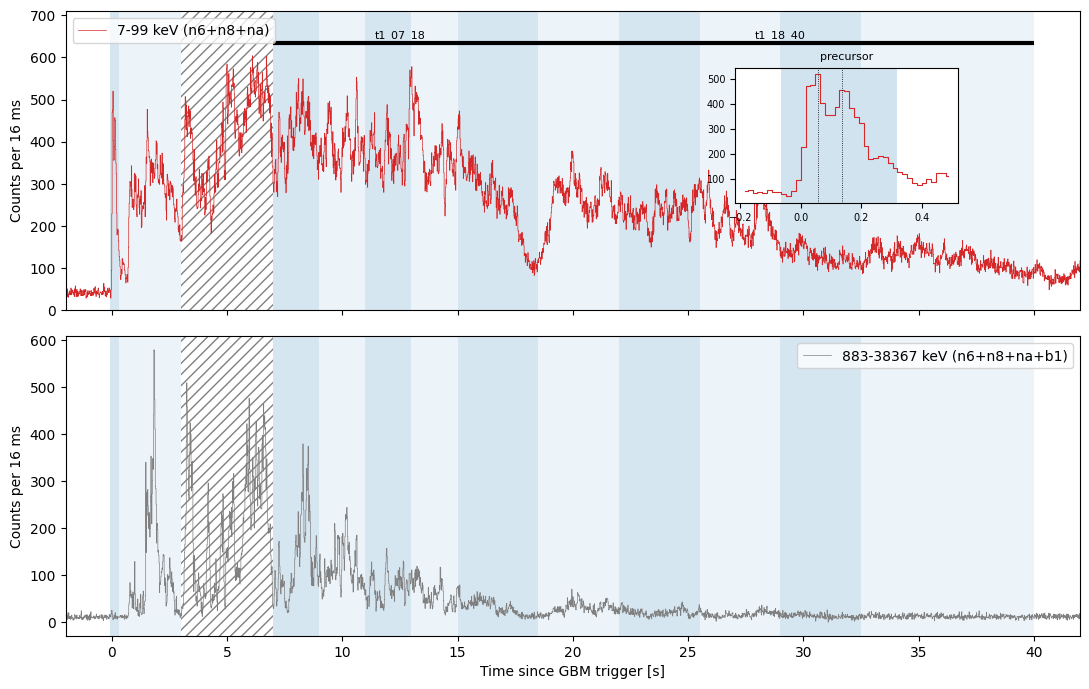

In [3]:
edges = aligned_bin_edges((-5.0, 45.0), 0.016)
centres = 0.5 * (edges[:-1] + edges[1:])
soft = sum(band_counts(DATA_DIR, BURST_ID, d, SOFT_BAND, edges) for d in SOFT_DETECTORS)
hard = sum(band_counts(DATA_DIR, BURST_ID, d, HARD_BAND, edges) for d in HARD_DETECTORS)

# the two precursor peaks, from the soft band
pre_bins = (centres > PRECURSOR[0]) & (centres < PRECURSOR[1])
first = pre_bins & (centres < 0.08)
second = pre_bins & (centres >= 0.08)
peaks = [centres[first][np.argmax(soft[first])], centres[second][np.argmax(soft[second])]]
print(f"precursor peaks at {peaks[0]:.3f} s and {peaks[1]:.3f} s; window {PRECURSOR[0]} to {PRECURSOR[1]} s")
print(f"soft counts per bin at the window edges: {soft[np.searchsorted(centres, PRECURSOR[0])]:.0f} and "
      f"{soft[np.searchsorted(centres, PRECURSOR[1])]:.0f} (background ~42)")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, counts, colour, name in ((axes[0], soft, "tab:red", "7-99 keV (n6+n8+na)"),
                                 (axes[1], hard, "grey", "883-38367 keV (n6+n8+na+b1)")):
    ax.step(centres, counts, where="mid", color=colour, lw=0.5, label=name)
    for i, (label, row) in enumerate(in_table2.iterrows()):
        ax.axvspan(row.t_start, row.t_stop, color="tab:blue", alpha=0.08 if i % 2 else 0.18, lw=0)
    ax.axvspan(*BAD_TIME_INTERVAL, facecolor="none", hatch="///", edgecolor="grey", lw=0)
    ax.set_ylabel("Counts per 16 ms")
    ax.legend(loc="upper left" if ax is axes[0] else "upper right")
top = soft.max() * 1.05
for label in ("t1_07_18", "t1_18_40"):
    axes[0].plot(WIN[label], [top, top], color="black", lw=3, solid_capstyle="butt")
    axes[0].text(np.mean(WIN[label]), top * 1.02, label, ha="center", fontsize=8)
axes[0].set_ylim(0, top * 1.12)
axes[1].set_xlabel("Time since GBM trigger [s]")
axes[1].set_xlim(-2, 42)

inset = axes[0].inset_axes([0.66, 0.36, 0.22, 0.45])
zoom = (centres > -0.2) & (centres < 0.5)
inset.step(centres[zoom], soft[zoom], where="mid", color="tab:red", lw=0.8)
inset.axvspan(*PRECURSOR, color="tab:blue", alpha=0.2, lw=0)
for p in peaks:
    inset.axvline(p, color="black", lw=0.6, ls=":")
inset.set_title("precursor", fontsize=8)
inset.tick_params(labelsize=7)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "12_windows_lightcurve.png", dpi=200)
plt.show()

Both precursor peaks (0.056 and 0.136 s) are inside Dichiara's window. Its start is at background (39 counts
per bin against ~42), but its end is not (128): for GRB 230307A the precursor runs into the main emission
without a quiet gap, so the 0.320 s edge is a choice rather than the end of the emission. I keep Dichiara's
edges so that the comparison is like for like.

## 2. Spectra and responses for every window

`make_spectra` fits each detector's background once and integrates it over every window, so all windows
share one background model per detector. For the response, a window inside one DRM uses that DRM; a window
crossing a boundary gets, for each 0.256 s of the window, the DRM nearest in time, weighted by the counts in
that 0.256 s (GDT's `Rsp2.weighted`).

Everything is written to `spectra/time_resolved/` (PHA, BAK, RSP per window and detector) with the fixed
response writer from notebook 08. The precursor products have to come out identical to notebook 08's.

In [4]:
spectra, bkg_chi2, responses, response_type = {}, {}, {}, {}
for det in SPECTRAL_DETECTORS:
    spectra[det], bkg_chi2[det] = make_spectra(DATA_DIR, BURST_ID, det, WIN, BKG_WINDOWS, BKG_ORDER)
    for label, window in WIN.items():
        responses[det, label], response_type[det, label] = window_response(DATA_DIR, BURST_ID, det, window)
print("background reduced chi2:", {d: round(c, 3) for d, c in bkg_chi2.items()})

for det in SPECTRAL_DETECTORS:
    for label in WIN:
        pha, bkg = spectra[det][label]
        stem = f"{BURST_ID}_{det}_{label}"
        pha.write(OUT_DIR, filename=stem + ".pha", overwrite=True)
        Bak.from_data(bkg, gti=pha.gti, trigger_time=pha.trigtime).write(
            OUT_DIR, filename=stem + ".bak", rates=True, overwrite=True)
        write_rsp(responses[det, label], OUT_DIR, stem + ".rsp")

# regression against notebook 08
p08, b08, r08 = load_spectra(CODE_DIR / "spectra", BURST_ID, SPECTRAL_DETECTORS)
for det, p, b, r in zip(SPECTRAL_DETECTORS, p08, b08, r08):
    pha, bkg = spectra[det]["pre"]
    assert np.array_equal(pha.data.counts, p.data.counts) and np.allclose(bkg.counts, b.data.counts)
    assert np.allclose(responses[det, "pre"].drm.matrix, r.drm.matrix, rtol=1e-6)
print("precursor spectra, backgrounds and responses identical to notebook 08")

response_table = pd.Series({label: response_type["n6", label] for label in WIN}, name="response")
response_table[response_table != "single DRM"]

background reduced chi2: {'n6': np.float64(0.974), 'n8': np.float64(0.956), 'na': np.float64(0.962), 'b1': np.float64(0.995)}


precursor spectra, backgrounds and responses identical to notebook 08


m10         counts-weighted
t1_18_40    counts-weighted
Name: response, dtype: str

## 3. Checks per window

Live fraction (1 - dead time), background fraction, net counts and S/N, per detector and window. S/N is net
counts over sqrt(total + sigma_B^2).

In [5]:
rows = []
for label, (t0, t1) in WIN.items():
    for det in SPECTRAL_DETECTORS:
        pha, bkg = spectra[det][label]
        total = float(np.sum(pha.data.counts))
        background = float(np.sum(bkg.counts))
        net = total - background
        rows.append(dict(label=label, detector=det, live_fraction=pha.exposure / (t1 - t0),
                         total=total, bkg_fraction=background / total, net=net,
                         snr=net / np.sqrt(total + np.sum(bkg.count_uncertainty**2))))
checks = pd.DataFrame(rows)
summary = checks.groupby("label", sort=False).agg(
    min_live_fraction=("live_fraction", "min"), max_bkg_fraction=("bkg_fraction", "max"),
    net_counts=("net", "sum"), min_snr=("snr", "min"))
summary.round(3)

,min_live_fraction,max_bkg_fraction,net_counts,min_snr
label,,,,
pre,0.955,0.372,11519.212,23.487
m01,0.913,0.158,194404.724,126.218
m02,0.887,0.118,202486.878,131.932
m03,0.897,0.130,185311.057,124.412
m04,0.923,0.166,147116.008,105.562
m05,0.930,0.192,126684.500,95.043
m06,0.957,0.320,121773.739,81.306
m07,0.957,0.332,117481.070,78.255
m08,0.962,0.381,96537.975,67.494


**Dead time against script 06.** Script 06 found the live fraction going down to ~0.77 in b1 in 16 ms bins.
Per window the PHA gives the live fraction averaged over the window; the 16 ms minimum inside each window
shows how deep it goes. The window average from the 16 ms bins (weighted by bin width) has to equal the
PHA's, since both are GDT's live time from the same events binned differently.

In [6]:
rows = []
for label, (t0, t1) in WIN.items():
    bins = np.append(np.arange(t0, t1, 0.016), t1)
    for det in SPECTRAL_DETECTORS:
        lf = live_fraction(DATA_DIR, BURST_ID, det, bins)
        widths = np.diff(bins)
        rows.append(dict(label=label, detector=det, min_16ms=lf.min(),
                         at_time=0.5 * (bins[:-1] + bins[1:])[lf.argmin()],
                         average_16ms=np.sum(lf * widths) / (t1 - t0),
                         pha=spectra[det][label][0].exposure / (t1 - t0)))
dead = pd.DataFrame(rows)
print("largest difference between the two averages:", f"{np.abs(dead.average_16ms - dead.pha).max():.1e}")
deepest = dead.loc[dead.groupby("label", sort=False).min_16ms.idxmin()].set_index("label")
deepest[["detector", "min_16ms", "at_time", "pha"]].round(3)

largest difference between the two averages: 3.3e-16


,detector,min_16ms,at_time,pha
label,,,,
pre,na,0.917,0.136,0.955
m01,b1,0.774,1.848,0.913
m02,b1,0.801,8.304,0.887
m03,b1,0.838,10.208,0.897
m04,b1,0.873,12.928,0.923
m05,na,0.887,13.008,0.930
m06,na,0.912,15.040,0.957
m07,na,0.932,19.996,0.957
m08,na,0.947,25.494,0.962


**Soft-band counts against script 05.** Script 05 corrects each 16 ms bin for its own dead time; a spectrum
has one live time for the whole window. With the same background model, the difference between the two is
only how the dead time is averaged, so I compute both and the averaging term separately. If they add up, the
spectra and the light curves are consistent. The averaging term is also a real effect on the fitted flux:
a fit to the whole window returns the live-time-weighted mean rate, which is lower than the true mean when
the brightest moments have the most dead time. Any spectrum accumulated over a window has this property,
whatever software made it, so it doesn't affect the comparison with Dichiara.

In [7]:
bkg_fits = {d: fit_background(DATA_DIR, BURST_ID, d, BKG_WINDOWS, BKG_ORDER)[0] for d in SOFT_DETECTORS}
rows = []
for label, (t0, t1) in WIN.items():
    bins = np.append(np.arange(t0, t1, 0.016), t1)
    per_bin = one_live = spectrum_route = 0.0
    for det in SOFT_DETECTORS:
        raw = band_counts(DATA_DIR, BURST_ID, det, SOFT_BAND, bins)
        lf = live_fraction(DATA_DIR, BURST_ID, det, bins)
        bkg_counts, _ = background_in_band(bkg_fits[det], SOFT_BAND, bins)   # rate x bin width, as in 05
        pha, bkg = spectra[det][label]
        f_mean = pha.exposure / (t1 - t0)
        per_bin += np.sum(raw / lf) - bkg_counts.sum()
        one_live += raw.sum() / f_mean - bkg_counts.sum()
        lo, hi = pha.data.lo_edges, pha.data.hi_edges
        band = (hi > SOFT_BAND[0]) & (lo < SOFT_BAND[1])
        spectrum_route += (np.sum(np.asarray(pha.data.counts)[band]) - np.sum(bkg.counts[band])) / f_mean
    rows.append(dict(label=label, script05_per_bin=per_bin, one_live_fraction=one_live,
                     spectrum=spectrum_route, averaging_effect_pct=100 * (per_bin / one_live - 1)))
soft_check = pd.DataFrame(rows).set_index("label")
soft_check["spectrum_vs_one_live_pct"] = 100 * (soft_check.spectrum / soft_check.one_live_fraction - 1)
soft_check.round(2)

,script05_per_bin,one_live_fraction,spectrum,averaging_effect_pct,spectrum_vs_one_live_pct
label,,,,,
pre,5994.94,5904.20,5904.20,1.54,0.00
m01,39201.76,38799.38,38801.51,1.04,0.01
m02,50057.41,49887.87,49887.87,0.34,0.00
m03,47435.12,47353.04,47354.07,0.17,0.00
m04,45210.11,45117.98,45119.06,0.20,0.00
m05,44966.08,44828.86,44828.86,0.31,0.00
m06,48779.99,48470.82,48470.82,0.64,0.00
m07,49047.41,48924.52,48924.52,0.25,0.00
m08,44026.40,43987.67,43988.68,0.09,0.00


**Data gaps.** The same test as script 06 (a gap longer than 20 mean waiting times is lost data), now
inside each window. GDT can't know that photons were lost in a gap, so it counts the gap as live time; the
fraction below is how much each window's exposure is overstated, which lowers the fitted flux by the same
fraction and leaves the spectral shape alone.

In [8]:
rows = []
for det in SPECTRAL_DETECTORS:
    starts, lengths = data_gaps(DATA_DIR, BURST_ID, det, (-1.0, 45.0))
    for label, (t0, t1) in WIN.items():
        inside = (starts >= t0) & (starts < t1)
        if inside.any():
            rows.append(dict(label=label, detector=det, gaps=int(inside.sum()),
                             at=", ".join(f"{s:.3f}" for s in starts[inside]),
                             total_ms=1e3 * lengths[inside].sum(),
                             exposure_overstated_pct=100 * lengths[inside].sum() / spectra[det][label][0].exposure))
gaps = pd.DataFrame(rows)
gaps.round(3)

,label,detector,gaps,at,total_ms,exposure_overstated_pct
0,pre,n6,1,0.003,2.098,0.554
1,m01,n6,1,1.730,1.162,0.045
2,m04,n6,1,11.970,1.396,0.072
3,t1_07_18,n6,1,11.970,1.396,0.013
4,pre,na,1,0.004,1.786,0.487
5,m01,na,1,1.730,1.076,0.043
6,m04,na,1,11.970,1.284,0.069
7,t1_07_18,na,1,11.970,1.284,0.013
8,pre,b1,1,0.004,1.402,0.374
9,m01,b1,3,"1.456, 1.458, 1.730",1.846,0.075


The 1.4-2.1 ms gap right after the trigger (T0 + 3-4 ms, in n6, na and b1) sits inside the precursor window and makes
its exposure 0.4-0.6% too long, so the precursor flux is low by about that much (within its 1.2% error); the
other gaps are ~1 ms in windows of several seconds and don't matter.

**The windows next to 3-7 s.** 0.32-3 s (m01) and 7-9 s (m02) touch it. They have the deepest dead time outside
3-7 s (b1 down to 0.77 and 0.80 in 16 ms bins), but no data gaps beyond ~1 ms each. Those gaps aren't the only
problem: the GBM team report pile-up in na at 2.5-7.5 s and in b1 at 2.5-11 s (GCN 33551), which takes in the end of
m01, all of m02 and m03 in b1, and a third of the 7-18 s window. I keep these windows to compare with Dichiara, and
notebook 15 works out what the pile-up does to E_peak.

## 4. Band fits

For the main emission I start every fit from a grid of 18 shapes (E_peak 200, 450 or 900 keV; alpha -0.6 or
-1.2; beta -2.6, -4 or -6) plus Dichiara's Table 2 values, each with the amplitude set so the model reproduces
the observed net counts.
Starting beta both shallow and steep matters: in some windows beta is so weakly constrained that a fit started on
the steep side slides to GDT's beta = -10 limit (in 18.5-22 s that is a local minimum Delta C ~ 1 above the best fit).
Every fit is then restarted with a second minimiser from its best point ("polish"). As a check, each Table 2
window is also fitted from Dichiara's values alone: if their solution sat in a different minimum, this fit
would end somewhere else.

In [9]:
GRID = [[1.0, e, a, b, 100.0] for e in (200.0, 450.0, 900.0) for a in (-0.6, -1.2) for b in (-2.6, -4.0, -6.0)]

def window_data(label, rsp_override=None, bkg_override=None, ranges=(FIT_RANGE_NAI, FIT_RANGE_BGO), dets=None):
    dets = dets or SPECTRAL_DETECTORS
    phas = [spectra[d][label][0] for d in dets]
    baks = [(bkg_override or {}).get(d, spectra[d][label][1]) for d in dets]
    rsps = [(rsp_override or {}).get(d, responses[d, label]) for d in dets]
    masks = [channel_mask(r, ranges[1] if d.startswith("b") else ranges[0]) for r, d in zip(rsps, dets)]
    return phas, baks, rsps, masks

def fit_band(data, extra=(), shapes=()):
    band = Band()
    starts = scaled_starts(band, *data, GRID + [list(s) for s in shapes]) + [list(s) for s in extra]
    fit = fit_model(*data, band, starts, polish=True)
    return band, fit

def table2_start(label):
    if label not in TABLE2.index:
        return []
    return [[1.0, TABLE2.Epeak[label], TABLE2.alpha[label], TABLE2.beta[label], 100.0]]

band_fits = {}
for label in WIN:
    data = window_data(label)
    band, fit = fit_band(data, shapes=table2_start(label))
    band_fits[label] = dict(data=data, band=band, fit=fit)

from_table2 = {}
for label in TABLE2.index:
    data, alone = band_fits[label]["data"], Band()
    fit = fit_model(*data, alone, scaled_starts(alone, *data, table2_start(label)), polish=True)
    from_table2[label] = (fit.parameters[1] - band_fits[label]["fit"].parameters[1],
                          cstat(fit) - cstat(band_fits[label]["fit"]))
shift = np.array(list(from_table2.values()))
print(f"started from Table 2 alone: E_peak within {np.abs(shift[:, 0]).max():.3f} keV and C-stat within "
      f"{np.abs(shift[:, 1]).max():.4f} of the best fit in all {len(shift)} windows")

fit_table = pd.DataFrame({label: dict(Epeak=f["fit"].parameters[1], alpha=f["fit"].parameters[2],
                                      beta=f["fit"].parameters[3], cstat=cstat(f["fit"]), dof=f["fit"].dof,
                                      converged=f["fit"].success)
                          for label, f in band_fits.items()}).T
fit_table["cstat_per_dof"] = fit_table.cstat / fit_table.dof
fit_table["dichiara_cstat_per_dof"] = TABLE2.cstat / TABLE2.dof
fit_table

started from Table 2 alone: E_peak within 0.246 keV and C-stat within 0.0020 of the best fit in all 12 windows


,Epeak,alpha,beta,cstat,dof,converged,cstat_per_dof,dichiara_cstat_per_dof
pre,170.299878,-0.633609,-2.952887,568.647729,484,True,1.174892,1.173125
m01,914.040819,-0.467634,-5.453344,953.380646,484,True,1.969795,1.967835
m02,967.339674,-0.709282,-4.456427,966.273884,484,True,1.996434,1.914433
m03,945.581866,-0.737913,-4.854146,1005.443085,484,True,2.077362,2.111753
m04,802.154134,-0.883739,-4.81535,1250.639398,484,True,2.583966,2.526392
m05,780.921757,-1.044053,-4.648447,1244.353121,484,True,2.570978,2.478351
m06,630.922271,-1.145285,-4.4057,1208.97382,484,True,2.49788,2.443711
m07,615.373049,-1.199869,-4.392558,1296.884882,484,True,2.679514,2.598351
m08,468.675752,-1.241154,-4.364302,1116.305492,484,True,2.306416,2.079794
m09,402.98456,-1.468101,-4.91432,1002.084971,484,True,2.070423,1.994433


All fits converge, and the fits started from Dichiara's Table 2 values alone end on the same minimum (E_peak
within 0.25 keV, C-stat within 0.002), so there is no second solution near theirs. The fit quality is the same
as Dichiara's window by window: C-stat/dof 1.17 for the precursor (theirs 1.17) and 1.43-2.68 for the main emission (theirs 1.45-2.60). The main-emission fits
aren't formally good, for them or for me: with 35,000-200,000 net counts per window, small departures from
the Band shape show up (section 12 finds where). The two windows next to 3-7 s are ordinary in fit quality (1.97
and 2.00), but at C-stat/dof ~2 that wouldn't show a distortion of a few percent, so it says little about pile-up
(notebook 15 estimates that directly). The long Table 1 windows fit
worst (6.3 and 5.9), as expected: E_peak changes a lot inside them, so one Band shape is a compromise.

## 5. Errors

Profile likelihood (Delta C = 1, the other parameters refitted) for E_peak, alpha and beta in every window, with the
refits also started from beta = -3 and -6. Covariance errors alongside. Where beta isn't constrained on the steep
side (the C-stat doesn't rise by 1 before beta = -10), I quote a 95% upper limit instead (Delta C = 2.71).

In [10]:
NAMES = ["A", "Epeak", "alpha", "beta"]
rows = []
for label, f in band_fits.items():
    band, fit, data = f["band"], f["fit"], f["data"]
    extra = [list(band.default_values[:3]) + [b, 100.0] for b in (-3.0, -6.0)]
    cov_err = np.sqrt(np.diag(covariance(fit)))
    row = dict(label=label)
    for i in (1, 2, 3):
        lo, hi = profile_error(*data, band, fit, i, extra_starts=extra)
        row.update({f"{NAMES[i]}_lo": lo, f"{NAMES[i]}_hi": hi, f"{NAMES[i]}_cov": cov_err[i]})
    if np.isnan(row["beta_lo"]):
        _, up95 = profile_error(*data, band, fit, 3, delta=2.71, extra_starts=extra)
        row["beta_upper95"] = fit.parameters[3] + up95
    rows.append(row)
    f["cov_err"] = cov_err
errors = pd.DataFrame(rows).set_index("label")
errors["Epeak_profile_over_cov"] = (errors.Epeak_lo + errors.Epeak_hi) / 2 / errors.Epeak_cov
errors.round(3)

,Epeak_lo,Epeak_hi,Epeak_cov,alpha_lo,alpha_hi,alpha_cov,beta_lo,beta_hi,beta_cov,beta_upper95,Epeak_profile_over_cov
label,,,,,,,,,,,
pre,5.310,5.313,5.252,0.043,0.045,0.044,0.104,0.091,0.094,NaN,1.011
m01,5.247,5.279,5.247,0.006,0.006,0.006,0.361,0.260,0.282,NaN,1.003
m02,6.998,7.007,6.964,0.005,0.005,0.005,0.164,0.143,0.149,NaN,1.006
m03,6.923,6.895,6.845,0.005,0.005,0.005,0.279,0.225,0.232,NaN,1.009
m04,7.497,7.221,7.233,0.005,0.005,0.005,0.421,0.311,0.306,NaN,1.017
m05,8.872,8.834,8.702,0.005,0.005,0.005,0.506,0.323,0.318,NaN,1.017
m06,8.261,8.306,8.095,0.006,0.006,0.006,0.520,0.342,0.310,NaN,1.023
m07,9.030,9.529,8.699,0.006,0.006,0.006,2.057,0.391,0.339,NaN,1.067
m08,8.079,7.971,7.257,0.007,0.007,0.007,NaN,0.560,0.501,-3.615,1.106


Profile and covariance errors on E_peak agree to within 11% in every window (the largest difference is in
22-25.5 s), so the likelihood is close to Gaussian in E_peak. Up to 29 s my alpha errors in the main emission are
0.005-0.007, half of Dichiara's 0.01, which is probably their rounding to two decimals; in the two faintest
windows they are 0.009-0.013, the same as theirs. beta is the weak parameter: from 22 s on its steep side isn't
constrained, so there the table gives a 95% upper limit; this matches their large beta errors (up to +/-7.4).

## 6. Flux

10-1000 keV energy flux in each window, with the error propagated from the covariance matrix (as in notebook
10).

In [11]:
flux_rows = {}
for label, f in band_fits.items():
    flux, err = flux_with_error(f["band"], f["fit"], FLUX_RANGE)
    flux_rows[label] = dict(flux=flux / 1e-5, flux_err=err / 1e-5)
flux_table = pd.DataFrame(flux_rows).T
flux_table.round(4)

,flux,flux_err
pre,3.3226,0.0408
m01,12.9992,0.0340
m02,17.5098,0.0444
m03,15.7246,0.0418
m04,11.6473,0.0347
m05,9.4638,0.0306
m06,4.8184,0.0164
m07,4.5477,0.0159
m08,3.5399,0.0143
m09,2.4807,0.0117


## 7. Independent check of the likelihood and the forward-folding

Everything above relies on GDT for two steps: folding the model through the response, and the likelihood.
To check both, I recompute the C-stat at every best fit with my own code:

$$C = 2\sum_i \left[ m_i + b_i - N_i + N_i \ln\frac{N_i}{m_i + b_i} \right]$$

summed over the fitted channels of all four detectors, where N_i are the observed counts, b_i the background
counts and m_i the model counts. For m_i I fold the model two ways: as GDT does (model at the centre of each
photon bin x bin width), and by integrating the model over each photon bin (8-point Gauss-Legendre in log E).
The first must reproduce GDT's C-stat exactly; the second shows how much GDT's midpoint shortcut matters.

In [12]:
nodes, weights = np.polynomial.legendre.leggauss(8)

def fold(rsp, function, params, integrate):
    drm = rsp.drm
    lo, hi = np.asarray(drm.photon_bins.low_edges()), np.asarray(drm.photon_bins.high_edges())
    if integrate:
        u_lo, u_hi = np.log(lo), np.log(hi)
        half = 0.5 * (u_hi - u_lo)
        energies = np.exp(half[:, None] * nodes + 0.5 * (u_hi + u_lo)[:, None])
        flux = function.eval(params, energies.ravel()).reshape(energies.shape)
        photons = np.sum(half[:, None] * weights * flux * energies, axis=1)       # dE = E du
    else:
        photons = function.eval(params, np.sqrt(lo * hi)) * (hi - lo)
    return photons @ np.asarray(drm.matrix)

def cstat_by_hand(data, function, params, integrate):
    total = 0.0
    for pha, bak, rsp, mask in zip(*data):
        n = np.asarray(pha.data.counts, dtype=float)[mask]
        b = np.asarray(bak.counts if hasattr(bak, "counts") else bak.data.counts)[mask]
        mu = fold(rsp, function, params, integrate)[mask] * pha.exposure + b
        term = mu - n
        term[n > 0] += n[n > 0] * np.log(n[n > 0] / mu[n > 0])
        total += 2 * term.sum()
    return total

rows = {}
for label, f in band_fits.items():
    params = f["band"].default_values
    rows[label] = dict(gdt=cstat(f["fit"]),
                       by_hand_midpoint=cstat_by_hand(f["data"], f["band"], params, integrate=False),
                       by_hand_integrated=cstat_by_hand(f["data"], f["band"], params, integrate=True))
likelihood_check = pd.DataFrame(rows).T
likelihood_check["midpoint_minus_gdt"] = likelihood_check.by_hand_midpoint - likelihood_check.gdt
likelihood_check["integrated_minus_midpoint"] = likelihood_check.by_hand_integrated - likelihood_check.by_hand_midpoint
likelihood_check.round(4)

,gdt,by_hand_midpoint,by_hand_integrated,midpoint_minus_gdt,integrated_minus_midpoint
pre,568.6477,568.6477,568.6147,0.0000,-0.0331
m01,953.3806,953.3806,953.6512,-0.0000,0.2706
m02,966.2739,966.2739,966.0072,-0.0000,-0.2667
m03,1005.4431,1005.4430,1005.2156,-0.0000,-0.2275
m04,1250.6394,1250.6394,1250.3419,-0.0000,-0.2975
m05,1244.3531,1244.3531,1244.1591,-0.0000,-0.1940
m06,1208.9738,1208.9738,1208.8055,-0.0000,-0.1683
m07,1296.8849,1296.8849,1296.7106,-0.0000,-0.1743
m08,1116.3055,1116.3055,1116.1628,-0.0000,-0.1427
m09,1002.0850,1002.0850,1002.0426,-0.0000,-0.0424


My C-stat matches GDT's to 0.0001 in every window, so the likelihood and the folding do what I think they do.
Integrating over each photon bin instead of the midpoint shortcut shifts the C-stat by at most 0.3 in the
Table 2 windows (0.8 in the long 7-18 s window). What matters for the fit is whether that shift changes as
the parameters move: below, the difference is evaluated with E_peak moved by +/-1 sigma. If it changes by delta per sigma
of E_peak (`change_over_1sigma`), the best-fit E_peak moves by about delta/2 sigma.

In [13]:
rows = {}
for label, f in band_fits.items():
    params = np.array(f["band"].default_values, dtype=float)
    diff = []
    for shift in (-1, 0, 1):
        trial = params.copy()
        trial[1] += shift * f["cov_err"][1]
        diff.append(cstat_by_hand(f["data"], f["band"], trial, True) - cstat_by_hand(f["data"], f["band"], trial, False))
    rows[label] = dict(at_minus_1sigma=diff[0], at_best=diff[1], at_plus_1sigma=diff[2],
                       change_over_1sigma=0.5 * (diff[2] - diff[0]))
fold_sensitivity = pd.DataFrame(rows).T
print(f"largest change across +-1 sigma: {fold_sensitivity.change_over_1sigma.abs().max():.3f}")
fold_sensitivity.round(4)

largest change across +-1 sigma: 0.287


,at_minus_1sigma,at_best,at_plus_1sigma,change_over_1sigma
pre,0.0074,-0.0331,-0.0767,-0.0421
m01,0.4746,0.2706,0.0653,-0.2046
m02,-0.0879,-0.2667,-0.4449,-0.1785
m03,-0.0695,-0.2275,-0.3848,-0.1576
m04,-0.1711,-0.2975,-0.4254,-0.1272
m05,-0.0941,-0.1940,-0.2931,-0.0995
m06,-0.0719,-0.1683,-0.2656,-0.0968
m07,-0.0826,-0.1743,-0.2658,-0.0916
m08,-0.0657,-0.1427,-0.2203,-0.0773
m09,-0.0043,-0.0424,-0.0813,-0.0385


The difference between the two folds changes by at most 0.20 per sigma of E_peak in the Table 2 windows (0.29 in
7-18 s), so the midpoint shortcut moves E_peak by at most ~0.1 sigma.

## 8. Windows crossing the 30.40 s response boundary

m10 (29-32.5 s) and t1_18_40 (18-40 s) use counts-weighted responses. The alternatives are the single DRM
nearest the window centre, or the DRMs interpolated to the centre.

In [14]:
rows = []
for label in ("m10", "t1_18_40"):
    t0, t1 = WIN[label]
    rsp2 = {d: GbmRsp2.open(rsp2_path(DATA_DIR, BURST_ID, d)) for d in SPECTRAL_DETECTORS}
    options = {"counts-weighted": None,
               "nearest DRM": {d: rsp2[d].nearest_drm(0.5 * (t0 + t1)) for d in SPECTRAL_DETECTORS},
               "interpolated": {d: rsp2[d].interpolate(0.5 * (t0 + t1)) for d in SPECTRAL_DETECTORS}}
    ref = band_fits[label]
    for name, override in options.items():
        band, fit = fit_band(window_data(label, rsp_override=override), extra=[ref["band"].default_values])
        rows.append(dict(window=label, response=name, Epeak=fit.parameters[1], alpha=fit.parameters[2],
                         cstat=cstat(fit), Epeak_shift_sigma=(fit.parameters[1] - ref["fit"].parameters[1]) / ref["cov_err"][1]))
pd.DataFrame(rows).round(3)

,window,response,Epeak,alpha,cstat,Epeak_shift_sigma
0,m10,counts-weighted,321.869,-1.471,691.265,-0.000
1,m10,nearest DRM,319.584,-1.485,689.447,-0.225
2,m10,interpolated,322.439,-1.468,692.080,0.056
3,t1_18_40,counts-weighted,450.296,-1.362,2875.436,0.000
4,t1_18_40,nearest DRM,451.090,-1.354,2931.118,0.188
5,t1_18_40,interpolated,449.917,-1.367,2850.535,-0.090


E_peak moves by at most 0.23 sigma in 29-32.5 s and 0.19 sigma in 18-40 s, so for E_peak the response choice doesn't
matter. In the long 18-40 s window it does matter for the fit quality (C-stat from 2851 with the interpolated
response to 2931 with the nearest DRM), as the response changes over those 22 s.

## 9. Comparison with Dichiara Table 2

Differences in units of the combined statistical errors (mine and theirs). Dichiara's main-emission errors
are statistical only and very small (E_peak +/-5-10 keV on ~800 keV, alpha +/-0.01), so a difference of a few sigma here
can come from analysis choices; the systematic errors in section 11 put that in context.

In [15]:
comparison = pd.DataFrame(index=TABLE2.index)
for col in ("Epeak", "alpha", "beta"):
    mine = fit_table.loc[TABLE2.index, col].astype(float)
    my_err = 0.5 * (errors.loc[TABLE2.index, f"{col}_lo"].fillna(errors.loc[TABLE2.index, f"{col}_hi"])
                    + errors.loc[TABLE2.index, f"{col}_hi"])
    comparison[col] = mine
    comparison[f"{col}_dichiara"] = TABLE2[col]
    comparison[f"{col}_sigma"] = (mine - TABLE2[col]) / np.hypot(my_err, TABLE2[f"{col}_err"])
comparison["flux"] = flux_table.loc[TABLE2.index, "flux"]
comparison["flux_dichiara"] = TABLE2.flux
comparison["flux_diff_pct"] = 100 * (comparison.flux / TABLE2.flux - 1)
comparison.round(2)

,Epeak,Epeak_dichiara,Epeak_sigma,alpha,alpha_dichiara,alpha_sigma,beta,beta_dichiara,beta_sigma,flux,flux_dichiara,flux_diff_pct
label,,,,,,,,,,,,
pre,170.30,170.3,-0.00,-0.63,-0.63,-0.06,-2.95,-2.95,-0.02,3.32,3.32,-0.04
m01,914.04,914.6,-0.07,-0.47,-0.47,0.20,-5.45,-5.50,0.11,13.00,11.96,8.69
m02,967.34,968.0,-0.07,-0.71,-0.71,0.06,-4.46,-4.50,0.24,17.51,17.48,0.17
m03,945.58,946.8,-0.13,-0.74,-0.73,-0.71,-4.85,-4.80,-0.17,15.72,15.77,-0.29
m04,802.15,804.5,-0.23,-0.88,-0.90,1.43,-4.82,-5.00,0.34,11.65,11.70,-0.45
m05,780.92,781.7,-0.06,-1.04,-1.07,2.29,-4.65,-4.80,0.26,9.46,9.53,-0.73
m06,630.92,634.6,-0.32,-1.15,-1.17,2.15,-4.41,-4.50,0.16,4.82,4.92,-1.99
m07,615.37,617.2,-0.15,-1.20,-1.23,2.60,-4.39,-5.00,0.40,4.55,4.59,-0.96
m08,468.68,468.4,0.03,-1.24,-1.27,2.35,-4.36,-5.10,0.46,3.54,3.59,-1.50


E_peak agrees with Table 2 in all twelve windows: the largest difference is 0.8 sigma (25.5-29 s). beta agrees
everywhere, the flux agrees within 2% except in 0.32-3 s, and alpha agrees within 1.5 sigma except in 13-29 s. The two
exceptions are below.

**The 0.32-3 s flux.** E_peak, alpha, beta and the C-stat agree with Dichiara here, but my flux is ~9% higher. Two
explanations to test: they didn't correct for dead time, or their accumulation interval was slightly
different. The window starts and ends on the quiet sides of a bright pulse (rates printed below), so moving
its edges changes the mean flux.

In [16]:
m01 = WIN["m01"]
rate_edges = np.append(np.arange(m01[0], m01[1], 0.064), m01[1])
rate = sum(band_counts(DATA_DIR, BURST_ID, d, (8.0, 1000.0), rate_edges) for d in SOFT_DETECTORS) / np.diff(rate_edges)
print(f"8-1000 keV count rate (n6+n8+na): {rate[0]:.0f}/s at {m01[0]} s, peak {rate.max():.0f}/s at "
      f"{rate_edges[rate.argmax()]:.2f} s, {rate[-1]:.0f}/s at {m01[1]} s; mean {np.sum(rate * np.diff(rate_edges)) / (m01[1] - m01[0]):.0f}/s")
lf = {d: spectra[d]["m01"][0].exposure / (m01[1] - m01[0]) for d in SPECTRAL_DETECTORS}
print("live fractions in 0.32-3 s:", {d: round(v, 3) for d, v in lf.items()})
for label in ("m01", "m02"):
    f = flux_table.loc[label, "flux"]
    mean_live = np.mean([spectra[d][label][0].exposure / (WIN[label][1] - WIN[label][0]) for d in SPECTRAL_DETECTORS])
    print(f"{label}: flux {f:.3f}, without the dead-time correction ~{f * mean_live:.3f}, Dichiara {TABLE2.flux[label]}")

rows = []
for edges_try in [(0.320, 3.0), (0.256, 3.072), (0.128, 3.072), (0.0, 3.072), (0.320, 2.816), (0.384, 3.0)]:
    trial = {"trial": edges_try}
    sp = {d: make_spectra(DATA_DIR, BURST_ID, d, trial, BKG_WINDOWS, BKG_ORDER)[0]["trial"] for d in SPECTRAL_DETECTORS}
    rs = [window_response(DATA_DIR, BURST_ID, d, edges_try)[0] for d in SPECTRAL_DETECTORS]
    data = ([sp[d][0] for d in SPECTRAL_DETECTORS], [sp[d][1] for d in SPECTRAL_DETECTORS], rs,
            [channel_mask(r, FIT_RANGE_BGO if d.startswith("b") else FIT_RANGE_NAI) for r, d in zip(rs, SPECTRAL_DETECTORS)])
    band, fit = fit_band(data)
    rows.append(dict(window=f"{edges_try[0]}-{edges_try[1]} s", Epeak=fit.parameters[1], alpha=fit.parameters[2],
                     flux=energy_flux(band, fit.parameters) / 1e-5))
pd.DataFrame(rows).round(3)

8-1000 keV count rate (n6+n8+na): 8031/s at 0.32 s, peak 85172/s at 1.54 s, 18643/s at 3.0 s; mean 43222/s
live fractions in 0.32-3 s: {'n6': np.float64(0.967), 'n8': np.float64(0.977), 'na': np.float64(0.94), 'b1': np.float64(0.913)}
m01: flux 12.999, without the dead-time correction ~12.335, Dichiara 11.96
m02: flux 17.510, without the dead-time correction ~16.280, Dichiara 17.48


,window,Epeak,alpha,flux
0,0.32-3.0 s,914.041,-0.468,12.999
1,0.256-3.072 s,913.625,-0.488,12.482
2,0.128-3.072 s,910.309,-0.526,12.072
3,0.0-3.072 s,903.025,-0.566,11.791
4,0.32-2.816 s,926.830,-0.452,13.594
5,0.384-3.0 s,912.854,-0.459,13.338


Undoing the dead-time correction lowers the 0.32-3 s flux only to ~12.3, and it would break the 7-9 s window,
which agrees to 0.2% with the correction applied. Moving the edges can bring the flux down to Dichiara's
value, but only by starting the window 0.2-0.3 s earlier, which softens alpha as well (-0.53 to -0.57 against
their -0.47). So I
can't reproduce their 0.32-3 s flux and shape together with any change to the analysis.

A simpler possibility is a misprint in the table, 1.196 for 1.296. That can be tested, because Table 2 also gives the
C-stat, and a flux and a C-stat can only belong to the same fit if that flux fits the counts that well. So I work out the
C-stat at my best-fit shape with the flux set to each value, then let the shape move with the flux held at 1.196.
GECAM is an independent check on the flux, since it isn't involved in Dichiara's fit (time-mean of the bins in Moradi et
al. 2024, at their 6-8000 keV).

In [17]:
band_m01, fit_m01, data_m01 = band_fits["m01"]["band"], band_fits["m01"]["fit"], band_fits["m01"]["data"]
best_m01 = list(fit_m01.parameters) + [100.0]
flux_m01 = energy_flux(band_m01, best_m01)

def cstat_at_flux(flux, shape):
    trial = [1.0, *shape, 100.0]
    trial[0] = flux / energy_flux(band_m01, trial)
    return cstat_by_hand(data_m01, band_m01, trial, False)

print(f"my best fit: flux {flux_m01:.4e}, C-stat {cstat(fit_m01):.1f}; Table 2: flux 1.196e-04, C-stat {TABLE2.cstat['m01']}")
for trial_flux in (1.196e-4, 1.296e-4):
    print(f"same shape, flux {trial_flux:.3e}: C-stat {cstat_at_flux(trial_flux, best_m01[1:4]):.1f}, "
          f"my flux differs from it by {100 * (flux_m01 / trial_flux - 1):+.1f}%")
free_shape = minimize(lambda shape: cstat_at_flux(1.196e-4, shape), best_m01[1:4], method="Nelder-Mead",
                      options=dict(maxiter=400, xatol=0.01, fatol=0.05))
print(f"shape free, flux held at 1.196e-04: C-stat {free_shape.fun:.1f} at E_peak {free_shape.x[0]:.0f} keV, "
      f"alpha {free_shape.x[1]:.3f}, beta {free_shape.x[2]:.2f}")

# The same comparison in GECAM's band
wide = (6.0, 8000.0)
to_wide = energy_flux(band_m01, best_m01, wide) / flux_m01
gecam = pd.read_csv(WINDOWS_FILE.parent / "moradi2024_table1.csv", comment="#")
middle = 0.5 * (gecam.t_start + gecam.t_stop)
inside_m01 = gecam[(middle > m01[0]) & (middle < m01[1])]
covered = (inside_m01.t_stop - inside_m01.t_start).sum()
gecam_mean = np.sum(inside_m01.flux_erg_cm2_s * (inside_m01.t_stop - inside_m01.t_start)) / (m01[1] - m01[0])
print(f"\n6-8000 keV, 1e-4 erg/cm2/s: mine {energy_flux(band_m01, best_m01, wide) / 1e-4:.3f}, "
      f"Table 2 with 1.196: {1.196 * to_wide:.3f}, with 1.296: {1.296 * to_wide:.3f}, "
      f"GECAM + GBM table {gecam_mean / 1e-4:.3f} ({covered:.2f} s of the {m01[1] - m01[0]:.2f} s covered)")

my best fit: flux 1.2999e-04, C-stat 953.4; Table 2: flux 1.196e-04, C-stat 954.4
same shape, flux 1.196e-04: C-stat 2116.6, my flux differs from it by +8.7%
same shape, flux 1.296e-04: C-stat 954.9, my flux differs from it by +0.3%
shape free, flux held at 1.196e-04: C-stat 1931.3 at E_peak 945 keV, alpha -0.537, beta -5.43

6-8000 keV, 1e-4 erg/cm2/s: mine 2.016, Table 2 with 1.196: 1.855, with 1.296: 2.010, GECAM + GBM table 2.061 (2.60 s of the 2.68 s covered)


At my best-fit shape, a flux of 1.196 x 10^-4 erg cm^-2 s^-1 gives C = 2116.6, over a thousand above Table 2's 954.4, and
with the shape free it still only reaches 1931. A flux of 1.296 x 10^-4 gives 954.9, within 0.5 of theirs, and then my flux
differs from it by +0.3%, like the other windows. GECAM points the same way: in its band I get 2.016 x 10^-4, the
GECAM + GBM table has 2.061 x 10^-4 (with 2.60 s of the 2.68 s covered), and Table 2's 1.196 would be 1.855 x 10^-4. So
1.196 is very likely a misprint for 1.296. The arXiv version has the same number. From here I can't exclude a flux worked
out with a different exposure from the fit, so it's worth asking the authors.

**alpha in 13-29 s.** My alpha is 0.025-0.032 harder than Dichiara's in 13-29 s, 2.2-2.6 sigma on the combined errors.
The BGO edge, the response and the background order move alpha by at most ~0.015 (section 11), so none of them
explains it on its own; I flag it rather than force it.

## 10. Comptonized vs Band

A Comptonized model is a Band function with beta -> -infinity, so the drop in C-stat from Comptonized to Band shows
whether the high-energy tail is actually measured. As a rule of thumb Delta C > 9 (~3 sigma for one extra parameter)
means Band is needed; the boundary at beta -> -infinity makes that only approximate.

In [18]:
CPL_GRID = [[1.0, e, a, 100.0] for e in (200.0, 450.0, 900.0) for a in (-0.6, -1.2)]
rows = []
for label, f in band_fits.items():
    data = f["data"]
    cpl = Comptonized()
    starts = scaled_starts(cpl, *data, CPL_GRID) + [list(f["band"].default_values[:3]) + [100.0]]
    fit = fit_model(*data, cpl, starts, polish=True)
    f["cpl"], f["cpl_fit"] = cpl, fit
    dc = cstat(fit) - cstat(f["fit"])
    rows.append(dict(label=label, Epeak_band=f["fit"].parameters[1], Epeak_cpl=fit.parameters[1],
                     alpha_band=f["fit"].parameters[2], index_cpl=fit.parameters[2],
                     dC_cpl_minus_band=dc,
                     beta_constrained=not np.isnan(errors.loc[label, "beta_lo"]),
                     verdict="Band needed" if dc > 9 else ("marginal" if dc > 4 else "either")))
cpl_table = pd.DataFrame(rows).set_index("label")
cpl_table.round(2)

,Epeak_band,Epeak_cpl,alpha_band,index_cpl,dC_cpl_minus_band,beta_constrained,verdict
label,,,,,,,
pre,170.30,198.67,-0.63,-0.80,43.35,True,Band needed
m01,914.04,917.64,-0.47,-0.47,11.46,True,Band needed
m02,967.34,985.60,-0.71,-0.72,34.84,True,Band needed
m03,945.58,954.13,-0.74,-0.74,15.44,True,Band needed
m04,802.15,807.87,-0.88,-0.89,7.36,True,marginal
m05,780.92,786.50,-1.04,-1.05,5.73,True,marginal
m06,630.92,635.36,-1.15,-1.15,3.78,True,either
m07,615.37,620.47,-1.20,-1.20,0.97,True,either
m08,468.68,471.15,-1.24,-1.24,0.37,False,either


The high-energy tail is needed (Delta C > 9) in the precursor, 0.32-11 s and 7-18 s, marginal in 11-15 s and
18-40 s, and not detected from 15 s on (Delta C < 4). In those later windows the Comptonized and Band E_peak agree
within about 5 keV, so E_peak doesn't depend on the choice. Where the tail is needed they differ more: by 18 keV in
7-9 s and 28 keV for the precursor.

## 11. Systematic errors

Three analysis choices, each changed on its own in every window: the BGO lower edge (250 instead of
200 keV), the response (interpolated to the window centre instead of the DRM covering it), and the background
polynomial (order 2 instead of 3). The systematic error is the three shifts added in quadrature.

A fourth fit starts the NaI at 40 keV instead of 8 keV. It isn't an analysis choice in the same sense: it tests
whether the Band shape holds over the whole energy range (section 12), so I keep it out of the systematic error
and report it as its own column. So is a fifth, with na and b1 alone: the only detectors within 60 deg of the
burst (notebook 08), which is what the GBM catalogue's selection keeps (Gruber et al. 2014).

In [19]:
bkg_order2 = {}
for det in SPECTRAL_DETECTORS:
    sp2, _ = make_spectra(DATA_DIR, BURST_ID, det, WIN, BKG_WINDOWS, 2)
    for label in WIN:
        bkg_order2.setdefault(label, {})[det] = sp2[label][1]

rows = []
for label, f in band_fits.items():
    t0, t1 = WIN[label]
    interp = {d: GbmRsp2.open(rsp2_path(DATA_DIR, BURST_ID, d)).interpolate(0.5 * (t0 + t1)) for d in SPECTRAL_DETECTORS}
    variants = {"BGO from 250 keV": window_data(label, ranges=(FIT_RANGE_NAI, (250.0, 40000.0))),
                "interpolated response": window_data(label, rsp_override=interp),
                "background order 2": window_data(label, bkg_override=bkg_order2[label])}
    row = dict(label=label)
    for name, data in variants.items():
        band, fit = fit_band(data, extra=[f["band"].default_values])
        row[f"dEpeak {name}"] = fit.parameters[1] - f["fit"].parameters[1]
        row[f"dalpha {name}"] = fit.parameters[2] - f["fit"].parameters[2]
    band, fit = fit_band(window_data(label, ranges=((40.0, 900.0), FIT_RANGE_BGO)), extra=[f["band"].default_values])
    row["Epeak_NaI_from_40keV"] = fit.parameters[1]
    row["shift_Epeak_NaI_from_40keV"] = fit.parameters[1] - f["fit"].parameters[1]
    band, fit = fit_band(window_data(label, dets=["na", "b1"]), extra=[f["band"].default_values])
    row["shift_Epeak_na_b1"] = fit.parameters[1] - f["fit"].parameters[1]
    row["shift_alpha_na_b1"] = fit.parameters[2] - f["fit"].parameters[2]
    rows.append(row)
syst = pd.DataFrame(rows).set_index("label")
syst["Epeak_sys"] = np.sqrt((syst.filter(like="dEpeak")**2).sum(axis=1))
syst["alpha_sys"] = np.sqrt((syst.filter(like="dalpha")**2).sum(axis=1))
syst["Epeak_sys_over_stat"] = syst.Epeak_sys / errors.Epeak_cov
syst.round(3)

,dEpeak BGO from 250 keV,dalpha BGO from 250 keV,dEpeak interpolated response,dalpha interpolated response,dEpeak background order 2,dalpha background order 2,Epeak_NaI_from_40keV,shift_Epeak_NaI_from_40keV,shift_Epeak_na_b1,shift_alpha_na_b1,Epeak_sys,alpha_sys,Epeak_sys_over_stat
label,,,,,,,,,,,,,
pre,-4.856,0.013,0.523,0.012,-0.030,-0.001,188.250,17.950,3.098,0.020,4.884,0.017,0.930
m01,-4.039,0.003,-0.629,0.006,-0.000,-0.001,896.123,-17.918,4.161,0.001,4.088,0.007,0.779
m02,2.696,-0.002,-0.551,0.002,0.293,-0.000,984.294,16.954,12.213,0.004,2.767,0.003,0.397
m03,0.755,-0.001,-0.230,0.001,0.221,-0.001,970.705,25.123,10.172,0.007,0.820,0.001,0.120
m04,3.398,-0.003,-0.033,-0.000,-0.043,-0.000,841.767,39.613,12.598,0.009,3.398,0.003,0.470
m05,4.384,-0.004,0.088,-0.002,0.307,-0.001,829.736,48.814,13.524,0.008,4.396,0.004,0.505
m06,5.440,-0.007,-0.001,-0.003,0.264,-0.001,671.320,40.397,7.654,0.008,5.446,0.008,0.673
m07,8.807,-0.009,0.234,-0.006,0.475,-0.001,662.079,46.706,7.223,0.009,8.823,0.011,1.014
m08,4.030,-0.008,-0.392,-0.009,0.853,-0.001,500.983,32.307,12.717,0.007,4.138,0.012,0.570


The systematic error on E_peak is 0.6-8.8 keV, between 0.06 and 1.1 times the statistical error, mostly from
the BGO lower edge. It covers the analysis choices only, not how well GBM measures this burst (notebook 15). Starting the NaI at 40 keV moves E_peak much more: by -18 to +49 keV, 5-6 sigma in 11-22 s.
Section 12 is about why. With na and b1 alone E_peak comes out 0-14 keV higher than with all four detectors (up
to 1.8 sigma in the Table 2 windows) and alpha at most 0.02 harder: adding n6 and n8, as Dichiara do, pulls E_peak down
by up to about its statistical error. The GBM team recommend na and b1 alone for this burst (GCN 33551), so this is
a real choice, not only a check.

## 12. Detector consistency and the low-energy shape

In the brightest windows the dead time reaches ~10% (window average), and pile-up would distort the shape
differently in each detector, since they see different rates. So each NaI is fitted together with b1 on its
own: if the shapes are fine, all three pairs should give the same E_peak and alpha. All three share b1, so this can only
show pile-up in the NaI; b1 is tested in notebook 15.

They don't agree (table below), but not in the way pile-up would cause. n6 and n8 agree with each other in every
window; na is the odd one, and na is the only NaI with real effective area below ~40 keV (notebook 08). So
the decisive test is to give na the same coverage as n6 and n8 (40-900 keV). To check the iodine K-edge
(33 keV) separately, another fit removes only na's 30-40 keV channels. A mid-brightness (15-18.5 s) and a faint
window (32.5-40 s) show whether the effect depends on the count rate, as pile-up would.

In [20]:
def subset(label, dets, nai_range=FIT_RANGE_NAI, drop_na=None):
    phas, baks, rsps, masks = window_data(label, ranges=(nai_range, FIT_RANGE_BGO), dets=dets)
    if drop_na is not None:
        i = dets.index("na")
        lo, hi = np.asarray(rsps[i].ebounds.low_edges()), np.asarray(rsps[i].ebounds.high_edges())
        masks[i] = masks[i] & ~((hi > drop_na[0]) & (lo < drop_na[1]))
    return phas, baks, rsps, masks

SUBSETS = {"n6+b1": dict(dets=["n6", "b1"]), "n8+b1": dict(dets=["n8", "b1"]), "na+b1": dict(dets=["na", "b1"]),
           "na+b1, na from 40 keV": dict(dets=["na", "b1"], nai_range=(40.0, 900.0)),
           "na+b1, no na 30-40 keV": dict(dets=["na", "b1"], drop_na=(30.0, 40.0)),
           "all four": dict(dets=SPECTRAL_DETECTORS),
           "all four, NaI from 40 keV": dict(dets=SPECTRAL_DETECTORS, nai_range=(40.0, 900.0))}
rows = []
for label in ("m01", "m02", "m03", "m06", "m11"):
    ref = band_fits[label]
    for name, kw in SUBSETS.items():
        band, fit = fit_band(subset(label, **kw), extra=[ref["band"].default_values])
        err = np.sqrt(np.diag(covariance(fit)))
        rows.append(dict(window=label, fit=name, Epeak=fit.parameters[1], Epeak_err=err[1],
                         alpha=fit.parameters[2], alpha_err=err[2]))
detectors = pd.DataFrame(rows)
order = list(SUBSETS)
print("E_peak [keV]")
print(detectors.pivot(index="fit", columns="window", values="Epeak").loc[order].round(1).to_string())
print("\nE_peak error [keV]")
print(detectors.pivot(index="fit", columns="window", values="Epeak_err").loc[order].round(1).to_string())
print("\nalpha")
print(detectors.pivot(index="fit", columns="window", values="alpha").loc[order].round(3).to_string())

E_peak [keV]
window                       m01     m02    m03    m06    m11
fit                                                          
n6+b1                      892.5  1009.0  976.6  657.2  236.6
n8+b1                      890.9  1006.9  975.0  653.3  236.0
na+b1                      918.2   979.6  955.8  638.6  239.7
na+b1, na from 40 keV      898.0   987.8  971.8  670.3  249.4
na+b1, no na 30-40 keV     917.9   979.4  955.9  641.5  244.3
all four                   914.0   967.3  945.6  630.9  232.5
all four, NaI from 40 keV  896.1   984.3  970.7  671.3  241.2

E_peak error [keV]
window                     m01  m02  m03  m06  m11
fit                                               
n6+b1                      5.8  7.9  7.7  9.6  6.3
n8+b1                      6.0  8.1  7.8  9.7  7.9
na+b1                      5.4  7.2  7.0  8.5  5.1
na+b1, na from 40 keV      5.6  7.7  7.4  9.5  5.2
na+b1, no na 30-40 keV     5.5  7.2  7.0  8.5  5.4
all four                   5.2  7.0  6.8  8.1  4.5
a

n6 and n8 agree with each other in every window (E_peak within 4 keV). na+b1 differs from them by up to
30 keV in E_peak and 0.21 in alpha, in different directions in different windows. Removing only na's 30-40 keV
channels moves E_peak by at most 5 keV and alpha by at most 0.01, so it isn't the iodine K-edge. Starting na at
40 keV, like n6 and n8, brings its E_peak within 21 keV of theirs (under 2 sigma), but alpha still differs by ~0.1 in
7-9 s and 32.5-40 s. None of this grows with the count rate (32.5-40 s has 11 times fewer counts per second
than 7-9 s, and the fraction of piled-up events goes up in proportion to the rate), so these differences between
detectors don't come from pile-up.

Two things set na apart (notebook 08): it is the only NaI with effective area below 40 keV for this burst,
and the only one of the three that sees the burst from in front. n6 and n8 view it 134 deg and 94 deg off axis,
where the response relies on photons getting through the back and side of the detector and on scattering off
the spacecraft, which is probably harder to model than a source in front; the GBM catalogue only uses NaI
detectors within 60 deg of the source (Gruber et al. 2014), and the GBM team advise against n6 and n8 for this burst. So the differences can come from the energy range
or from the responses at those angles, and these detectors can't fully separate the two. What can be tested
is the first: with all four detectors, adding the NaI channels below 40 keV makes alpha harder in 7-11 s and
15-18.5 s and softer in 0.32-3 s and 32.5-40 s, so the data below ~40 keV don't follow the Band shape fitted
above it.

If the Band shape is what fails at low energies, a model with one more break below the peak should fit much
better. `BandLowBreak` (in `spectral_fit_tools.py`) is a Band function times a smooth break at E_b: slope
alpha1 below it, alpha2 between it and the peak, and exactly the Band function when E_b -> 0 or alpha1 = alpha2. It has two
more free parameters than Band. I fit it in every Table 2 window, starting from a grid of break energies and
from the Band best fit itself. A "clean" break is one inside the fitted range (above 8 keV and well below the
peak) with neither slope at its limit.

In [21]:
rows = []
for label in TABLE2.index:
    f = band_fits[label]
    A, epk, al, be = f["fit"].parameters
    model = BandLowBreak()
    shapes = [[1.0, eb, a1, a2, epk, be, 2.0, 100.0] for eb in (15.0, 30.0, 60.0, 120.0)
              for a1 in (-0.3, -0.67) for a2 in (al, al - 0.4)]
    starts = scaled_starts(model, *f["data"], shapes) + [[A, 2.0, al, al, epk, be, 2.0, 100.0]]
    fit = fit_model(*f["data"], model, starts, polish=True)
    eb, a1, a2, epk_lb, be_lb = fit.parameters[1:6]
    at_limit = np.isclose(a1, model.min_values[2], atol=1e-3) or np.isclose(a1, model.max_values[2], atol=1e-3)
    rows.append(dict(label=label, dC_band_minus_lowbreak=cstat(f["fit"]) - cstat(fit), Eb=eb, alpha1=a1, alpha2=a2,
                     Epeak_lowbreak=epk_lb, Epeak_band=epk,
                     clean_break=bool(FIT_RANGE_NAI[0] < eb < 0.5 * epk_lb and not at_limit)))
lowbreak = pd.DataFrame(rows).set_index("label")
lowbreak.round(3)

,dC_band_minus_lowbreak,Eb,alpha1,alpha2,Epeak_lowbreak,Epeak_band,clean_break
label,,,,,,,
pre,28.054,48.268,-0.240,-1.543,143.601,170.300,True
m01,142.880,13.973,-1.900,-0.389,893.977,914.041,False
m02,121.749,159.291,-0.628,-0.911,996.121,967.340,True
m03,140.677,55.680,-0.513,-0.853,977.607,945.582,True
m04,292.911,37.827,-0.420,-1.044,845.632,802.154,True
m05,324.947,28.704,-0.423,-1.202,832.928,780.922,True
m06,204.614,20.604,-0.445,-1.275,671.730,630.922,True
m07,265.000,18.590,-0.314,-1.343,663.615,615.373,True
m08,205.385,16.063,-0.222,-1.393,498.887,468.676,True


The extra break improves the C-stat by 23-325 for two more parameters in every window, far more than two
extra parameters give by chance. In the precursor and in 7-25.5 s the break is clean: it sits between 16
and 160 keV, with alpha1 = -0.2 to -0.6 below it and alpha2 = -0.9 to -1.5 above, and in the main emission it moves
down as the burst goes on (159 keV in 7-9 s, then 56, 38, 29, 21, 19 and 16 keV by 22-25.5 s), following
E_peak down. In 0.32-3 s, 25.5-29 s and 32.5-40 s it isn't clean (break below 8 keV, or a slope at its
limit), so there the extra freedom fits something in the lowest channels rather than a break inside the band;
29-32.5 s is borderline (break at 8.7 keV).

A calibration problem in na would sit at a fixed energy; a break that drifts smoothly from 160 to 16 keV and
tracks E_peak looks more like the spectrum itself. Two breaks like this have been reported in other bright
GBM bursts (e.g. Ravasio et al. 2019), where synchrotron emission would give slopes of -2/3 and -3/2, and in
GRB 211211A (Gompertz et al. 2023; notebook 14). But na is the only one of GBM's twelve NaI detectors with
real effective area below 40 keV for this burst (notebook 08), so GBM alone can't rule out its low-energy
calibration; that would need another instrument at low energies. What it means for this work:
- E_peak depends on how the low-energy part is modelled: the break model and the NaI-from-40-keV fits both
  move it by up to ~50 keV in 11-22 s. The results table keeps the Band E_peak (what Dichiara fit, and what
  matches Table 2) and gives the NaI-from-40-keV value next to it.
- For the precursor the break model (Delta C 28, break at 48 keV, alpha2 -1.54) improves the fit as much as Band +
  blackbody did (Delta C 27, notebook 10). These are probably the same low-energy feature seen two ways.

## 13. Check against the GBM catalogue

The GBM catalogue fits this burst with RMfit, P-stat (their FITS header says `PSTAT`, the same statistic as
mine), TTE data, na and b1 only (the detectors within 60 deg of the burst), NaI channels 5-123 and BGO channels 6-123 (8-900 keV and 300 keV-40 MeV),
over two intervals: the fluence interval (0-184.32 s) and the peak-flux interval (6.144-7.168 s). I repeat
their setup exactly, with my own background, and compare with the values read straight from the catalogue
files. Both intervals include part of the 3-7 s bad interval, and the fluence interval overlaps the end of my
background window, so this checks the pipeline rather than the physics.

I compare fluences, not the catalogue's flux: in the fluence interval their energy flux times 184.32 s is ~1.5
times their own fluence (it corresponds to an effective ~121 s), so their flux there isn't fluence over the
interval. Fluences below are in units of 10^-3 erg cm^-2.

In [22]:
def catalogue_fit(kind, model):
    with fits.open(DATA_DIR / f"glg_scat_all_{BURST_ID}_{kind}_{model}_v01.fit") as h:
        p = h["FIT PARAMS"].data
        values = [p[f"PARAM{i}"][0] for i in range(3)]
        return dict(t=tuple(p["TIMEBIN"][0]), Epeak=values[1][0], Epeak_err=values[1][1],
                    alpha=values[2][0], alpha_err=values[2][1], beta=p["PARAM3"][0][0] if model == "band" else np.nan,
                    fluence=p["NRGFLNC"][0][0], red_chi2=p["REDCHSQ"][0][0])

CAT_DETS = ["na", "b1"]
CAT_CHANNELS = {"na": np.arange(5, 124), "b1": np.arange(6, 124)}
rows = []
for kind in ("flnc", "pflx"):
    t0, t1 = catalogue_fit(kind, "band")["t"]
    sp = {d: make_spectra(DATA_DIR, BURST_ID, d, {"cat": (t0, t1)}, BKG_WINDOWS, BKG_ORDER)[0]["cat"] for d in CAT_DETS}
    rs = [window_response(DATA_DIR, BURST_ID, d, (t0, t1))[0] for d in CAT_DETS]
    data = ([sp[d][0] for d in CAT_DETS], [sp[d][1] for d in CAT_DETS], rs,
            [np.isin(np.arange(128), CAT_CHANNELS[d]) for d in CAT_DETS])
    for model in ("band", "comp"):
        cat = catalogue_fit(kind, model)
        if model == "band":
            function = Band()
            fit = fit_model(*data, function, scaled_starts(function, *data, GRID + [[1.0, 700.0, -1.0, -2.1, 100.0]]), polish=True)
        else:
            function = Comptonized()
            fit = fit_model(*data, function, scaled_starts(function, *data, CPL_GRID), polish=True)
        err = np.sqrt(np.diag(covariance(fit)))
        rows.append(dict(interval=f"{kind} {t0}-{t1} s", model=model, Epeak=fit.parameters[1], Epeak_err=err[1],
                         Epeak_catalogue=cat["Epeak"], Epeak_catalogue_err=cat["Epeak_err"],
                         alpha=fit.parameters[2], alpha_catalogue=cat["alpha"],
                         beta=fit.parameters[3] if model == "band" else np.nan, beta_catalogue=cat["beta"],
                         fluence_1e3=1e3 * energy_flux(function, fit.parameters) * (t1 - t0),
                         fluence_catalogue_1e3=1e3 * cat["fluence"],
                         catalogue_red_chi2=cat["red_chi2"]))
catalogue = pd.DataFrame(rows)
catalogue["fluence_diff_pct"] = 100 * (catalogue.fluence_1e3 / catalogue.fluence_catalogue_1e3 - 1)
catalogue.round(4)

,interval,model,Epeak,Epeak_err,Epeak_catalogue,Epeak_catalogue_err,alpha,alpha_catalogue,beta,beta_catalogue,fluence_1e3,fluence_catalogue_1e3,catalogue_red_chi2,fluence_diff_pct
0,flnc 0.0-184.32 s,band,952.2049,3.4732,692.207886,2.8341,-1.0380,-1.0062,-5.6327,-2.0001,2.8694,2.6653,93.1884,7.6579
1,flnc 0.0-184.32 s,comp,952.7015,3.4687,945.382324,3.2846,-1.0381,-1.0347,NaN,NaN,2.8694,2.8754,8.5663,-0.2071
2,pflx 6.144-7.168 s,band,1173.0483,8.2260,800.463501,6.2451,-0.5505,-0.4435,-6.5553,-2.0001,0.2760,0.2552,14.3577,8.1708
3,pflx 6.144-7.168 s,comp,1174.8653,8.0836,1175.205566,8.0895,-0.5514,-0.5495,NaN,NaN,0.2759,0.2757,0.9745,0.1012


In both intervals the catalogue's Band fit has beta stuck at -2.0001, the limit of the fit, and is poor
(reduced chi2 93 and 14), while their Comptonized fit is much better (8.6 and 0.97). My Band fits don't get stuck: beta
goes to -5.6 and -6.6, essentially a Comptonized shape. My Comptonized fits reproduce theirs: in the peak-flux
interval E_peak 1174.9 against 1175.2 keV, index -0.551 against -0.550, fluence within 0.1%; over the fluence
interval E_peak 952.7 +/- 3.5 against 945.4 +/- 3.3 keV (0.8%), index -1.038 against -1.035 and fluence within
0.2%, where the different backgrounds matter most. So the pipeline reproduces the GBM team's own analysis,
and their Band entries for this burst are stuck fits that shouldn't be used.

## 14. E_peak(t)

E_peak in each window over the light curve, with Dichiara's Table 2 values on top. Error bars are statistical
and systematic added in quadrature.

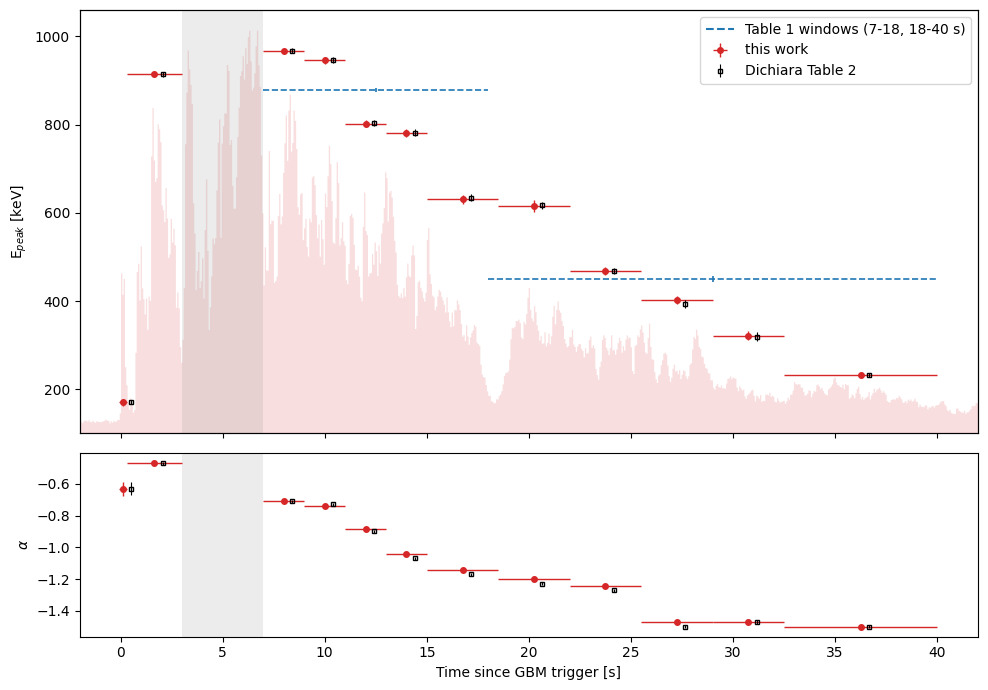

7-40 s: Spearman rho(E_peak, time) = -1.00, rho(E_peak, flux) = 1.00


In [23]:
lc_edges = aligned_bin_edges((-2.0, 42.0), 0.064)
lc_centres = 0.5 * (lc_edges[:-1] + lc_edges[1:])
lc = sum(band_counts(DATA_DIR, BURST_ID, d, (8.0, 1000.0), lc_edges) for d in SOFT_DETECTORS)

table2_labels = list(TABLE2.index)
mid = windows.loc[table2_labels, ["t_start", "t_stop"]].mean(axis=1)
half = windows.loc[table2_labels, "duration"] / 2
total_err = lambda lo, hi, sys: [np.hypot(np.asarray(lo), np.asarray(sys)), np.hypot(np.asarray(hi), np.asarray(sys))]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax = axes[0]
ax2 = ax.twinx()
ax2.fill_between(lc_centres, lc, step="mid", color="tab:red", alpha=0.15, lw=0)
ax2.set_yticks([])
ax.errorbar(mid, fit_table.loc[table2_labels, "Epeak"].astype(float), xerr=half,
            yerr=total_err(errors.loc[table2_labels, "Epeak_lo"], errors.loc[table2_labels, "Epeak_hi"],
                           syst.loc[table2_labels, "Epeak_sys"]),
            fmt="o", color="tab:red", ms=4, lw=1, label="this work")
ax.errorbar(mid + 0.4, TABLE2.Epeak, yerr=TABLE2.Epeak_err, fmt="s", color="black", ms=3, lw=0.8,
            mfc="none", label="Dichiara Table 2")
for label in ("t1_07_18", "t1_18_40"):
    t0, t1 = WIN[label]
    y = fit_table.loc[label, "Epeak"]
    e = np.hypot(errors.loc[label, "Epeak_cov"], syst.loc[label, "Epeak_sys"])
    ax.hlines(y, t0, t1, colors="tab:blue", linestyles="--", lw=1.2)
    ax.vlines(0.5 * (t0 + t1), y - e, y + e, colors="tab:blue", lw=1.2)
ax.plot([], [], color="tab:blue", ls="--", label="Table 1 windows (7-18, 18-40 s)")
ax.set_ylim(100, 1060)
ax2.set_ylim(0, 1.05 * lc.max())
for a in axes:
    a.axvspan(*BAD_TIME_INTERVAL, color="grey", alpha=0.15, lw=0)
ax.set_ylabel("E$_{peak}$ [keV]")
ax.legend(loc="upper right")
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)

axes[1].errorbar(mid, fit_table.loc[table2_labels, "alpha"].astype(float), xerr=half,
                 yerr=[errors.loc[table2_labels, "alpha_lo"], errors.loc[table2_labels, "alpha_hi"]],
                 fmt="o", color="tab:red", ms=4, lw=1)
axes[1].errorbar(mid + 0.4, TABLE2.alpha, yerr=TABLE2.alpha_err, fmt="s", color="black", ms=3, lw=0.8, mfc="none")
axes[1].set_ylabel(r"$\alpha$")
axes[1].set_xlabel("Time since GBM trigger [s]")
axes[1].set_xlim(-2, 42)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "12_epeak_time.png", dpi=200)
plt.show()

after_bti = [l for l in table2_labels if WIN[l][0] >= BAD_TIME_INTERVAL[1]]
rho_t = spearmanr(mid[after_bti], fit_table.loc[after_bti, "Epeak"].astype(float))
rho_f = spearmanr(flux_table.loc[after_bti, "flux"], fit_table.loc[after_bti, "Epeak"].astype(float))
print(f"7-40 s: Spearman rho(E_peak, time) = {rho_t.statistic:.2f}, rho(E_peak, flux) = {rho_f.statistic:.2f}")

The same hard-to-soft evolution as Dichiara: E_peak ~915-970 keV in the first windows, falling to ~230 keV
by 32.5-40 s, with alpha softening from about -0.5 to -1.5. After the bad interval, E_peak and the flux both fall
monotonically, so within this burst I can't tell hard-to-soft evolution from E_peak simply tracking the
intensity; 0.32-3 s (lower flux, E_peak 914 keV) against 7-9 s (higher flux, 967 keV) leans slightly towards
tracking.

## 15. The precursor: start, gap and its two pulses

The title of the project is about precursor properties, so here is the precursor's structure. Bayesian blocks
(Scargle et al. 2013; GDT's binned version) on the light curve of n6+n8+na at 8-1000 keV give its start, its
two pulses, and whether the rate goes back to background before the main emission (for GRB 211211A it does,
notebook 14). The bins have an edge on T0 like every other light curve here. 16 ms is the main binning; 8 and
32 ms check that the structure doesn't depend on it.

In [24]:
def precursor_blocks(bin_width, p0=0.05):
    edges = np.round(aligned_bin_edges((-1.0, 1.0), bin_width), 6)
    counts, exposure = 0, 0
    for d in SOFT_DETECTORS:
        tte = GbmTte.open(tte_path(DATA_DIR, BURST_ID, d))
        lc = tte.slice_energy((8.0, 1000.0)).to_phaii(bin_by_edges, edges).to_lightcurve()
        tte.close()
        counts, exposure = counts + lc.counts, exposure + lc.exposure / len(SOFT_DETECTORS)
    cp = bayesian_blocks(TimeBins(counts, edges[:-1], edges[1:], exposure), p0=p0)
    return pd.DataFrame({"start": edges[cp[:-1]], "stop": edges[cp[1:]],
                         "rate": [counts[a:b].sum() / exposure[a:b].sum() for a, b in zip(cp[:-1], cp[1:])]})

def structure(blocks):
    background_rate = blocks.rate.iloc[0]
    start = blocks.start[blocks.rate > 1.5 * background_rate].iloc[0]
    in_pre = blocks[(blocks.start >= start) & (blocks.stop <= 0.2)]
    first = in_pre.loc[in_pre[in_pre.stop <= 0.08].rate.idxmax()]
    second = in_pre.loc[in_pre[in_pre.start >= 0.08].rate.idxmax()]
    between = in_pre[(in_pre.start >= first.stop) & (in_pre.stop <= second.start)]
    dip = between.loc[between.rate.idxmin()] if len(between) else None
    after = blocks[(blocks.start >= second.stop) & (blocks.stop <= 0.8)]
    trough = after.loc[after.rate.idxmin()]
    span = lambda b: f"{b.start:.3f} to {b.stop:.3f}"
    return dict(pre_burst_rate=background_rate, start=start, pulse_1=span(first), pulse_2=span(second),
                dip=span(dip) if dip is not None else "none", dip_over_pulse_1=dip.rate / first.rate if dip is not None else np.nan,
                trough=span(trough), trough_over_pre_burst=trough.rate / background_rate, main_rise=trough.stop)

blocks = precursor_blocks(0.016)
check = pd.DataFrame({f"{1e3 * w:.0f} ms": structure(precursor_blocks(w)) for w in (0.008, 0.016, 0.032)}).T
print(check.round(3).to_string())
blocks[blocks.stop <= 0.8].round(3)

      pre_burst_rate  start         pulse_1         pulse_2             dip dip_over_pulse_1          trough trough_over_pre_burst main_rise
8 ms     3309.202646 -0.024  0.016 to 0.064  0.120 to 0.168  0.064 to 0.120         0.733642  0.560 to 0.704              1.827159     0.704
16 ms    3320.564059 -0.016  0.016 to 0.064  0.128 to 0.160  0.064 to 0.112         0.722791  0.560 to 0.704              1.820907     0.704
32 ms    3296.219297 -0.032  0.032 to 0.064  0.128 to 0.160  0.064 to 0.128         0.751847  0.544 to 0.704              1.885676     0.704


,start,stop,rate
0,-1.008,-0.016,3320.564
1,-0.016,0.000,11683.177
2,0.000,0.016,24774.497
3,0.016,0.064,49867.397
4,0.064,0.112,36043.691
5,0.112,0.128,42114.266
6,0.128,0.160,50189.583
7,0.160,0.176,38025.678
8,0.176,0.208,28049.114
9,0.208,0.224,17836.740


The precursor starts at -0.016 s (-0.024 and -0.032 s with 8 and 32 ms bins, so within a bin of T0). Its two
pulses are separate blocks at 0.016-0.064 s and 0.128-0.160 s, with a dip between them (0.064-0.112 s) where the
rate falls to 72% of the first pulse; 8 and 32 ms bins give the same pulses and dip to within a bin. After the
second pulse the rate decays but never returns to the pre-burst level: the lowest block before the main
emission (0.560-0.704 s) is still 1.8 times the pre-burst rate, and the main emission rises from 0.704 s, at
all three bin sizes. So in GRB 230307A the precursor runs into the main emission with no quiet gap, and
Dichiara's 0.320 s end is a cut inside the decay.

Each pulse gets its own spectrum, split at 0.096 s inside the dip; the two together are the whole precursor
window.

In [25]:
dip = structure(blocks)["dip"].split(" to ")
split = np.round(np.mean([float(x) for x in dip]) / 0.016) * 0.016           # middle of the dip, on the 16 ms grid
print(f"split at {split:.3f} s")
PULSES = {"pulse 1": (PRECURSOR[0], split), "pulse 2": (split, PRECURSOR[1])}
pulse_spectra = {d: make_spectra(DATA_DIR, BURST_ID, d, PULSES, BKG_WINDOWS, BKG_ORDER)[0] for d in SPECTRAL_DETECTORS}
rows = []
for name, window in PULSES.items():
    rs = [window_response(DATA_DIR, BURST_ID, d, window)[0] for d in SPECTRAL_DETECTORS]
    data = ([pulse_spectra[d][name][0] for d in SPECTRAL_DETECTORS], [pulse_spectra[d][name][1] for d in SPECTRAL_DETECTORS],
            rs, [channel_mask(r, FIT_RANGE_BGO if d.startswith("b") else FIT_RANGE_NAI) for r, d in zip(rs, SPECTRAL_DETECTORS)])
    net = sum(np.sum(p.data.counts) - np.sum(b.counts) for p, b in zip(data[0], data[1]))
    band, fit = fit_band(data)
    extra = [list(band.default_values[:3]) + [b, 100.0] for b in (-3.0, -6.0)]
    lo, hi = profile_error(*data, band, fit, 1, extra_starts=extra)
    err = np.sqrt(np.diag(covariance(fit)))
    cpl = Comptonized()
    cpl_fit = fit_model(*data, cpl, scaled_starts(cpl, *data, CPL_GRID) + [list(band.default_values[:3]) + [100.0]], polish=True)
    rows.append(dict(pulse=name, window=f"{window[0]}-{window[1]} s", net_counts=net, Epeak=fit.parameters[1],
                     Epeak_lo=lo, Epeak_hi=hi, alpha=fit.parameters[2], alpha_err=err[2], beta=fit.parameters[3],
                     beta_err=err[3], cstat=cstat(fit), dof=fit.dof, dC_cpl_minus_band=cstat(cpl_fit) - cstat(fit),
                     flux=energy_flux(band, fit.parameters) / 1e-5))
pulses = pd.DataFrame(rows).set_index("pulse")
whole = sum(np.sum(spectra[d]["pre"][0].data.counts) - np.sum(spectra[d]["pre"][1].counts) for d in SPECTRAL_DETECTORS)
assert np.isclose(pulses.net_counts.sum(), whole)
alpha_change = (pulses.alpha.iloc[1] - pulses.alpha.iloc[0]) / np.hypot(*pulses.alpha_err)
print(f"net counts of the two pulses add up to the whole precursor ({whole:.1f}); alpha changes by {alpha_change:.1f} sigma")
pulses.round(3)

split at 0.096 s


net counts of the two pulses add up to the whole precursor (11519.2); alpha changes by -3.8 sigma


,window,net_counts,Epeak,Epeak_lo,Epeak_hi,alpha,alpha_err,beta,beta_err,cstat,dof,dC_cpl_minus_band,flux
pulse,,,,,,,,,,,,,
pulse 1,-0.064-0.096 s,4899.591,172.013,7.588,7.72,-0.426,0.072,-2.809,0.104,445.965,484,42.281,3.478
pulse 2,0.096-0.32 s,6619.621,168.916,7.676,8.42,-0.769,0.056,-3.131,0.185,564.883,484,8.564,3.212


E_peak is the same in both pulses (172 +/- 8 and 169 +/- 8 keV), but alpha softens from -0.43 +/- 0.07 to -0.77 +/- 0.06
(3.8 sigma): the second pulse has relatively more photons at low energies. The first pulse clearly needs the Band
tail (Delta C 42 against a Comptonized fit), the second only marginally (Delta C 8.6). So the single Band fit over the
whole precursor, Dichiara's and mine, averages over a change of shape between the pulses, while E_peak itself
stays put.

## 16. Results table

One row per window, written to `shared/epeak_230307A.csv` for the merge with the MVT table (columns in
`shared/README.md`). beta is quoted as a 95% upper limit where its steep side isn't constrained. `Epeak_NaI40_keV`
is E_peak with the NaI starting at 40 keV (section 12): the spread between it and `Epeak_keV` is the model
dependence to keep in mind when comparing windows. Each row says which notebook and commit produced it.

In [26]:
def git(*args):
    return subprocess.run(["git", *args], cwd=CODE_DIR, capture_output=True, text=True).stdout.strip()

commit = git("rev-parse", "--short", "HEAD") + ("+uncommitted" if git("status", "--porcelain", ".") else "")

def notes_for(label):
    notes = []
    if response_type["n6", label] != "single DRM":
        notes.append("counts-weighted response (crosses the 30.40 s DRM boundary)")
    for det, interval in GBM_PILEUP.items():
        overlap = min(WIN[label][1], interval[1]) - max(WIN[label][0], interval[0])
        if overlap > 0:
            notes.append(f"{100 * overlap / (WIN[label][1] - WIN[label][0]):.0f}% inside the {det} pile-up interval")
    if label.startswith("t1"):
        notes.append("long window over strong E_peak evolution: time-averaged shape")
    g = gaps[gaps.label == label]
    if len(g) and g.exposure_overstated_pct.max() > 0.1:
        notes.append(f"data gap counted as live time, flux up to {g.exposure_overstated_pct.max():.1f}% low")
    if label in TABLE2.index:
        diff = 100 * (flux_table.loc[label, "flux"] / TABLE2.flux[label] - 1)
        if abs(diff) > 5:
            notes.append(f"flux {diff:+.0f}% from Table 2, which looks like a misprint (section 9)")
    if np.isnan(errors.loc[label, "beta_lo"]):
        notes.append("beta not constrained on the steep side")
    return "; ".join(notes)

results = pd.DataFrame({
    "label": list(WIN),
    "t_start": [WIN[l][0] for l in WIN], "t_stop": [WIN[l][1] for l in WIN],
    "dichiara_table": windows.dichiara_table.values,
    "model": "Band",
    "Epeak_keV": fit_table.Epeak.astype(float).values,
    "Epeak_err_lo": errors.Epeak_lo.values, "Epeak_err_hi": errors.Epeak_hi.values,
    "Epeak_sys": syst.Epeak_sys.values,
    "Epeak_NaI40_keV": syst.Epeak_NaI_from_40keV.values,
    "alpha": fit_table.alpha.astype(float).values,
    "alpha_err_lo": errors.alpha_lo.values, "alpha_err_hi": errors.alpha_hi.values,
    "alpha_sys": syst.alpha_sys.values,
    "beta": fit_table.beta.astype(float).values,
    "beta_err_lo": errors.beta_lo.values, "beta_err_hi": errors.beta_hi.values,
    "beta_upper95": errors.get("beta_upper95", pd.Series(np.nan, index=errors.index)).values,
    "flux_10_1000keV_erg_cm2_s": flux_table.flux.values * 1e-5,
    "flux_err": flux_table.flux_err.values * 1e-5,
    "cstat": fit_table.cstat.astype(float).values, "dof": fit_table.dof.astype(int).values,
    "Epeak_cpl_keV": cpl_table.Epeak_cpl.values, "dC_cpl_minus_band": cpl_table.dC_cpl_minus_band.values,
    "Epeak_rest_keV": fit_table.Epeak.astype(float).values * (1 + REDSHIFT),
    "notes": [notes_for(l) for l in WIN],
    "notebook": "12_time_resolved_spectra.ipynb", "commit": commit, "run_date": date.today().isoformat(),
})
# a limit replaces the lower error where beta is unconstrained below
results.loc[results.beta_upper95.notna(), "beta_err_lo"] = np.nan
results.to_csv(WINDOWS_FILE.parent / "epeak_230307A.csv", index=False, float_format="%.6g")

check = pd.read_csv(WINDOWS_FILE.parent / "epeak_230307A.csv")
assert list(check.label) == list(windows.index) and check.label.is_unique
assert check[["Epeak_keV", "Epeak_err_lo", "Epeak_err_hi", "flux_10_1000keV_erg_cm2_s"]].notna().all().all()
print(f"wrote {len(check)} windows, commit {commit}")
check[["label", "t_start", "t_stop", "Epeak_keV", "Epeak_err_lo", "Epeak_err_hi", "Epeak_sys", "alpha", "beta",
       "beta_upper95", "notes"]].round(3)

wrote 14 windows, commit 4f6328e+uncommitted


,label,t_start,t_stop,Epeak_keV,Epeak_err_lo,Epeak_err_hi,Epeak_sys,alpha,beta,beta_upper95,notes
0,pre,-0.064,0.32,170.300,5.310,5.313,4.884,-0.634,-2.953,NaN,"data gap counted as live time, flux up to 0.6%..."
1,m01,0.320,3.00,914.041,5.247,5.279,4.088,-0.468,-5.453,NaN,19% inside the na pile-up interval; 19% inside...
2,m02,7.000,9.00,967.340,6.998,7.007,2.767,-0.709,-4.456,NaN,25% inside the na pile-up interval; 100% insid...
3,m03,9.000,11.00,945.582,6.923,6.895,0.820,-0.738,-4.854,NaN,100% inside the b1 pile-up interval
4,m04,11.000,13.00,802.154,7.497,7.221,3.398,-0.884,-4.815,NaN,NaN
5,m05,13.000,15.00,780.922,8.872,8.834,4.396,-1.044,-4.648,NaN,NaN
6,m06,15.000,18.50,630.922,8.261,8.306,5.446,-1.145,-4.406,NaN,NaN
7,m07,18.500,22.00,615.373,9.030,9.529,8.823,-1.200,-4.393,NaN,NaN
8,m08,22.000,25.50,468.676,8.079,7.971,4.138,-1.241,-4.364,-3.615,beta not constrained on the steep side
9,m09,25.500,29.00,402.985,8.406,9.028,2.984,-1.468,-4.914,-3.706,beta not constrained on the steep side
